<center><h1>Hu_Tianyang_HW6</h1></center>

Name: Tianyang Hu
<br>
Github Username: hhuhhuhhuhhu
<br>
USC ID: 2203816542

## 1. Tree-Based Methods

Import packages

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.pipeline import Pipeline

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from xgboost import XGBClassifier

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 120

pd.set_option("display.max_columns", 20)

### (a) Download the APS Failure data

In [3]:
data_dir = Path(".")

train_df = pd.read_csv(
    data_dir / "aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)

test_df = pd.read_csv(
    data_dir / "aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)

X_train = train_df.drop(columns="class")
X_test = test_df.drop(columns="class")

y_train = train_df["class"].map({"neg": 0, "pos": 1})
y_test = test_df["class"].map({"neg": 0, "pos": 1})

print("Training data shape:", train_df.shape)
print("Test data shape:", test_df.shape)
print("Number of features:", X_train.shape[1])

display(train_df.head())

Training data shape: (60000, 171)
Test data shape: (16000, 171)
Number of features: 170


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

mean, median, mode, KNN, and iterative imputation

In [4]:
print("Missing values before imputation:")
print("Training:", X_train.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("\nMissing values after imputation:")
print("Training:", X_train_imputed.isna().sum().sum())
print("Test:", X_test_imputed.isna().sum().sum())

print("\nTraining features shape:", X_train_imputed.shape)
print("Test features shape:", X_test_imputed.shape)

Missing values before imputation:
Training: 850015
Test: 228680

Missing values after imputation:
Training: 0
Test: 0

Training features shape: (60000, 170)
Test features shape: (16000, 170)


#### (ii) Calculate the coefficient of variation

In [5]:
feature_means = X_train_imputed.mean()
feature_stds = X_train_imputed.std(ddof=1)

cv_values = feature_stds / feature_means.replace(0, np.nan)

cv_table = pd.DataFrame({
    "Mean": feature_means,
    "Sample SD": feature_stds,
    "CV": cv_values
}).sort_values("CV", ascending=False)

with pd.option_context("display.max_rows", 170):
    display(cv_table)

,Mean,Sample SD,CV
cf_000,1.431075e+05,3.504525e+07,244.887517
co_000,1.433300e+05,3.504525e+07,244.507385
ad_000,1.434383e+05,3.504525e+07,244.322816
cs_009,7.705097e+02,1.833278e+05,237.930554
dh_000,4.392641e+03,5.412441e+05,123.216097
dj_000,3.727133e+01,4.379166e+03,117.494225
ag_000,2.191577e+02,2.036364e+04,92.917755
as_000,1.254079e+02,1.095219e+04,87.332500
ay_009,1.149620e+03,9.741156e+04,84.733735
ak_000,9.076607e+02,7.299859e+04,80.424975


#### (iii) Plot a correlation matrix

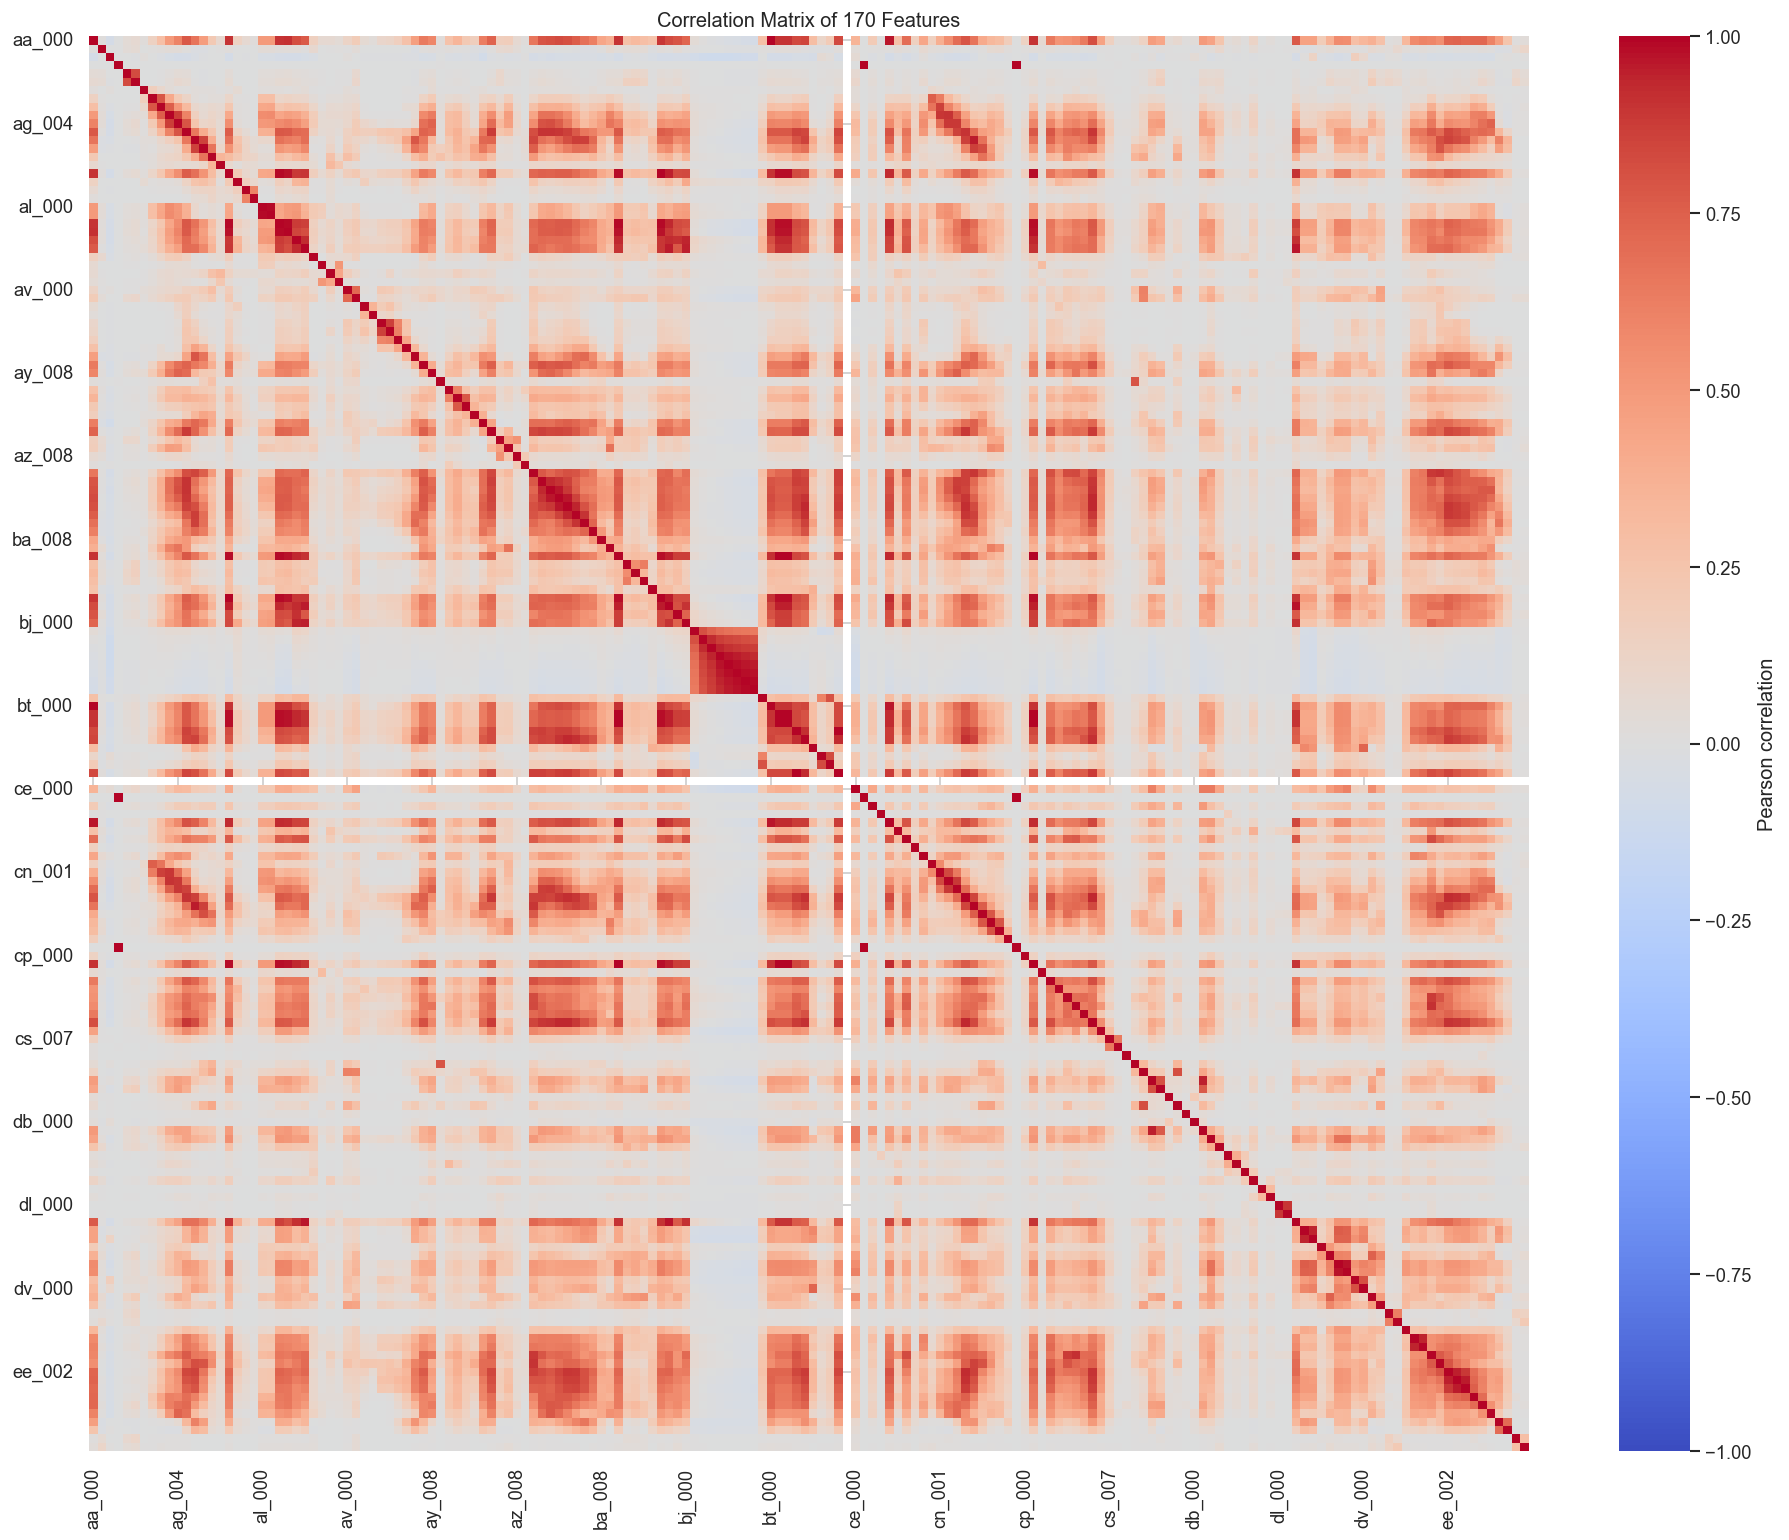

In [6]:
correlation_matrix = X_train_imputed.corr()

plt.figure(figsize=(16, 13))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=10,
    yticklabels=10,
    cbar_kws={"label": "Pearson correlation"}
)

plt.title("Correlation Matrix of 170 Features")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Several groups of features show strong positive correlations.
Most negative correlations appear weak.

#### (iv) Make scatter plots and box plots

Selected features:
['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


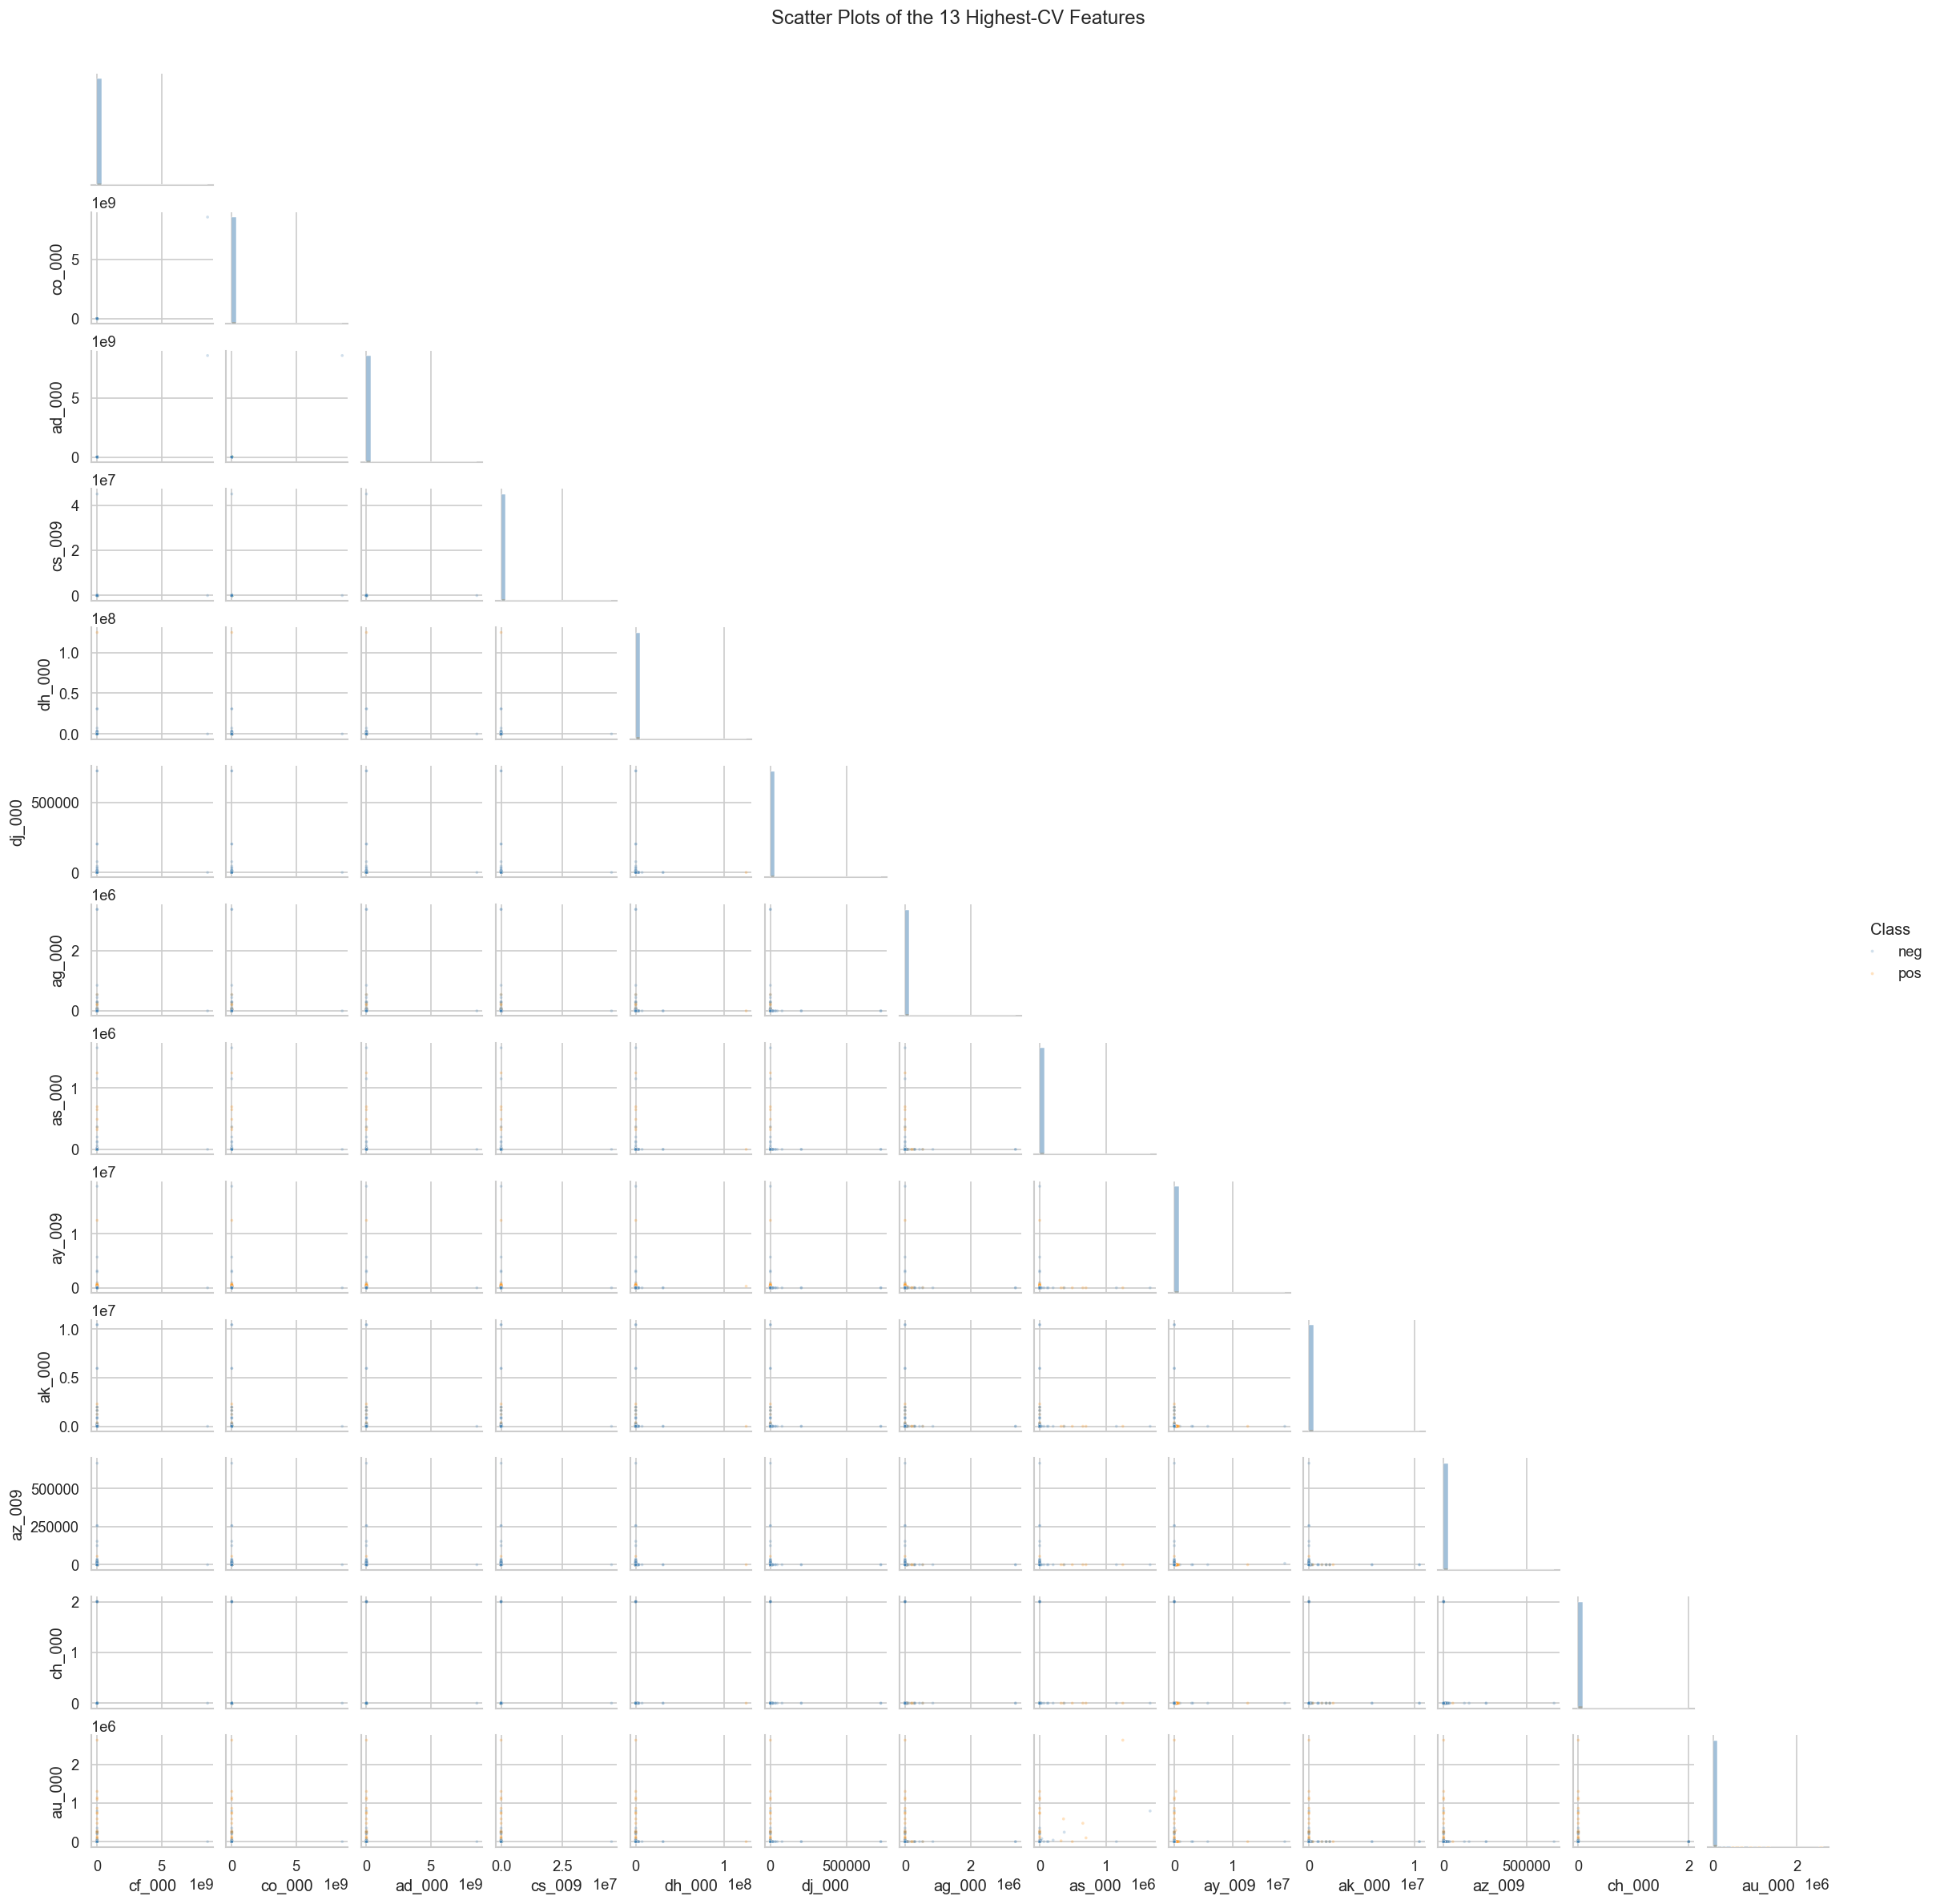

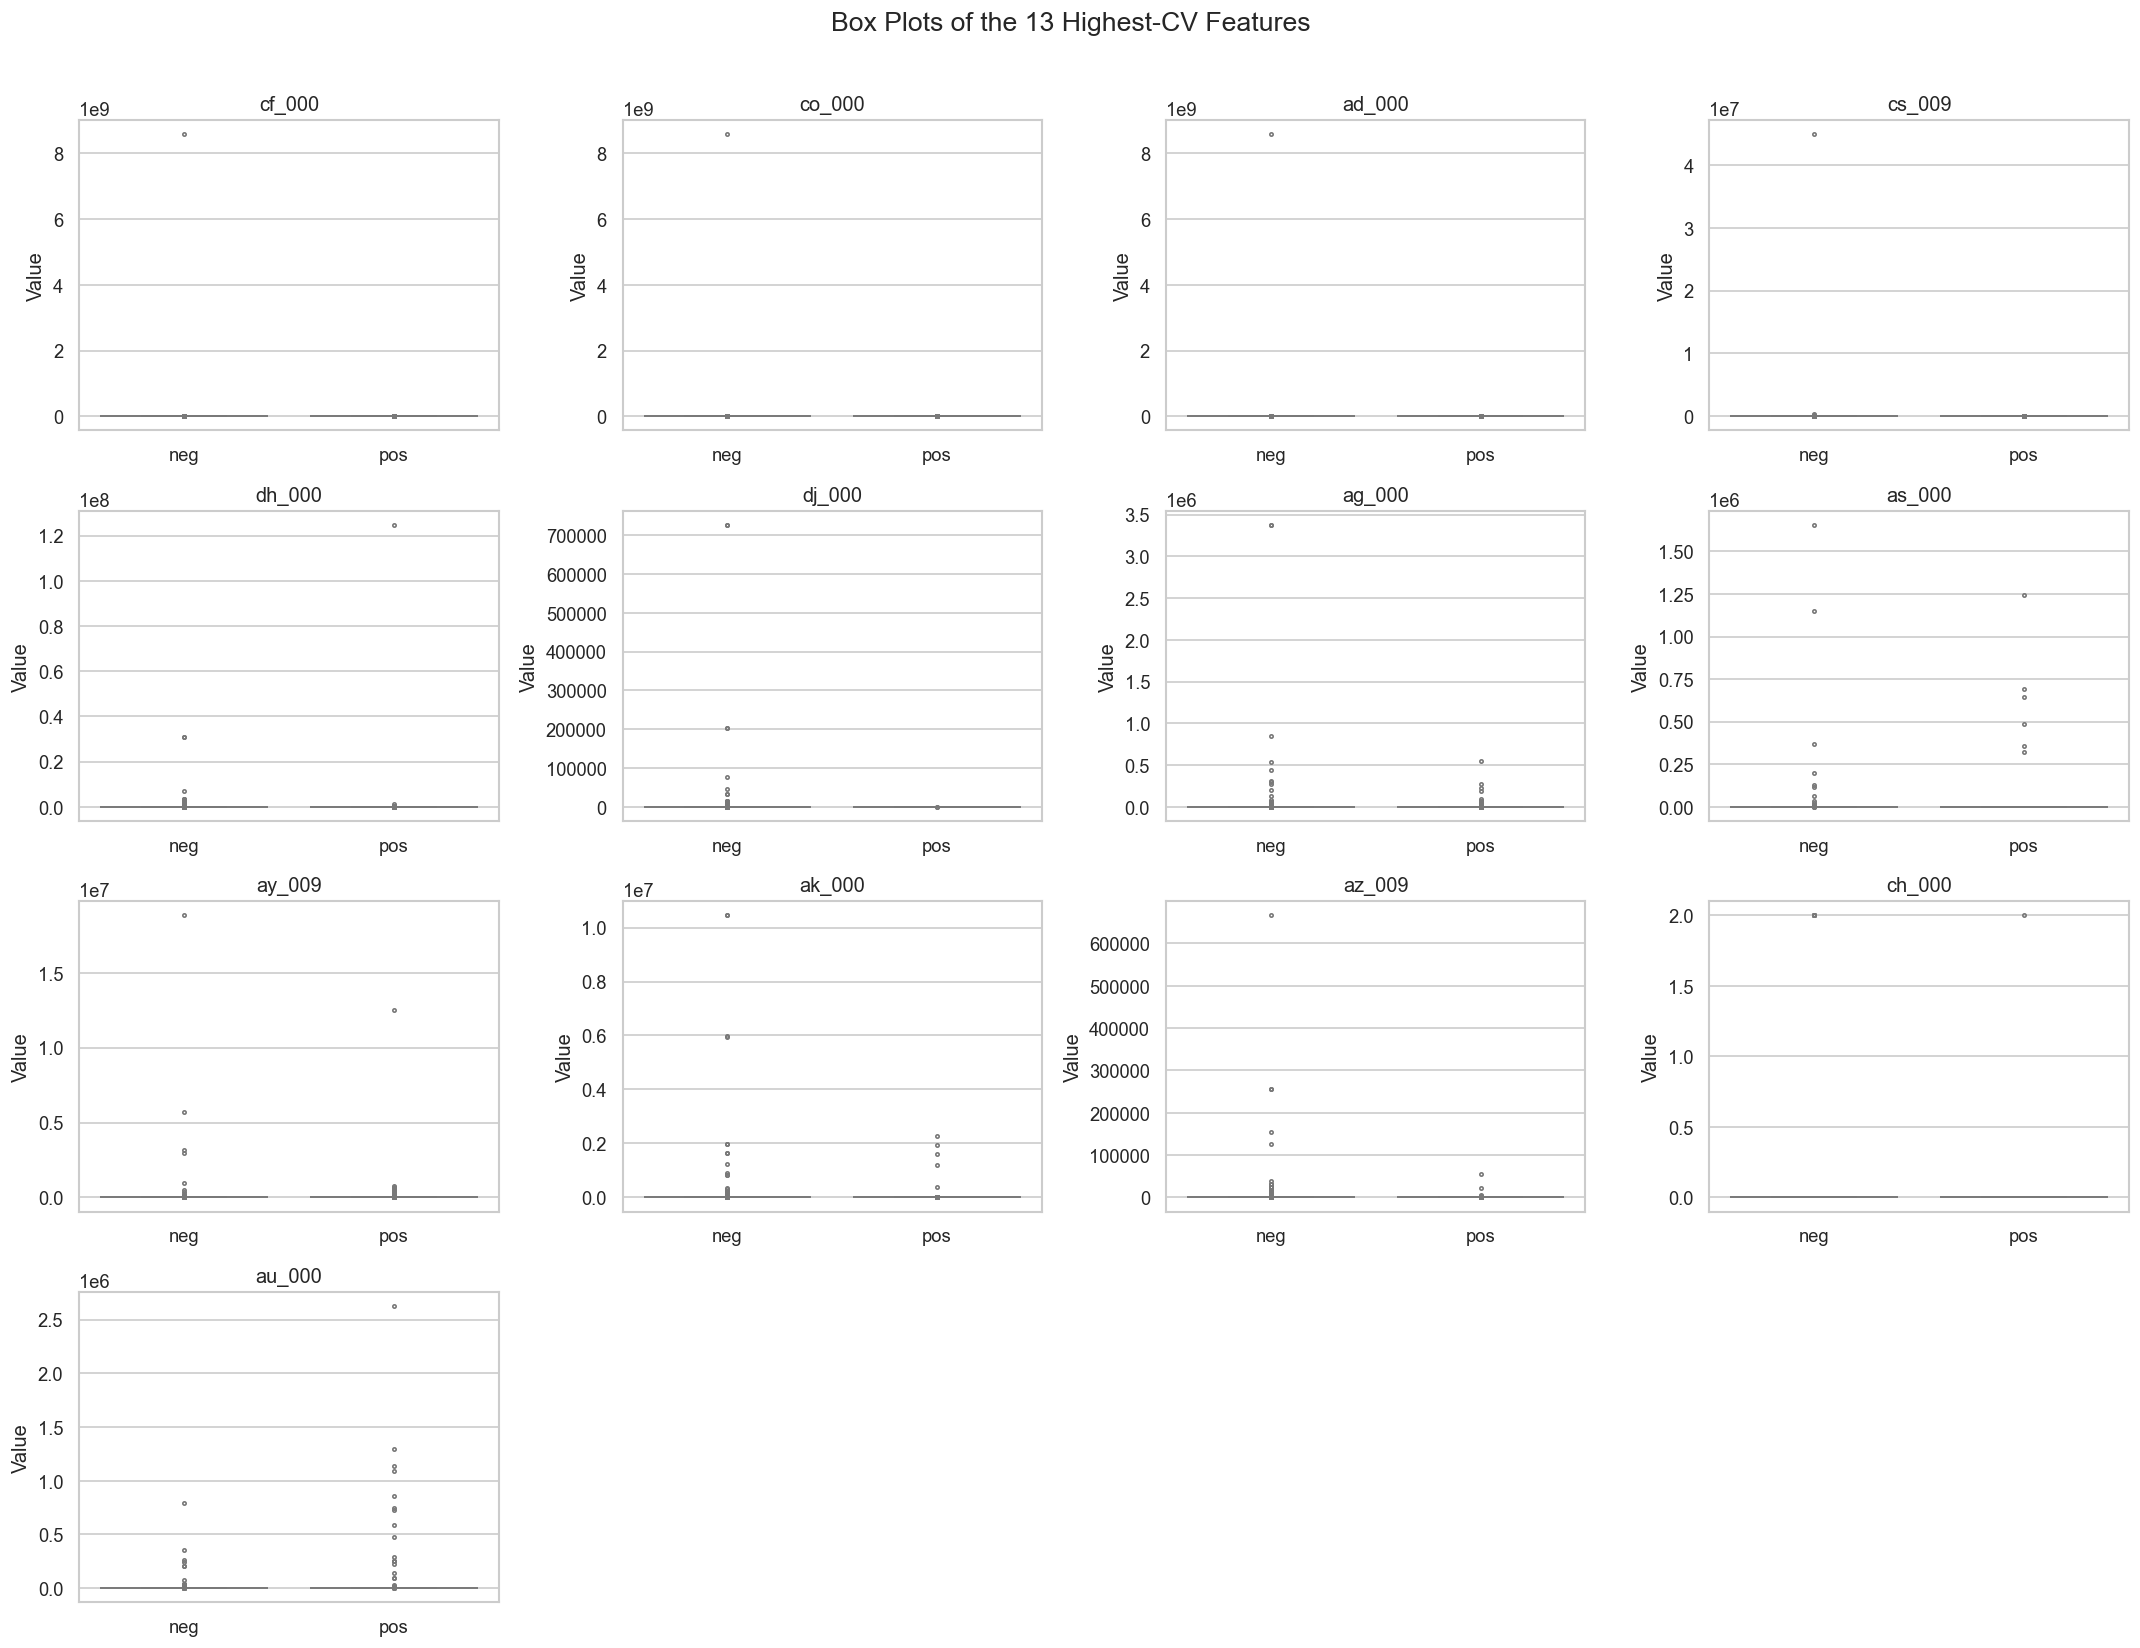

In [7]:
top_features = cv_table["CV"].dropna().head(13).index.tolist()

print("Selected features:")
print(top_features)

plot_data = X_train_imputed[top_features].copy()
plot_data["Class"] = y_train.map({0: "neg", 1: "pos"})

g = sns.pairplot(
    plot_data,
    vars=top_features,
    hue="Class",
    hue_order=["neg", "pos"],
    palette={"neg": "steelblue", "pos": "darkorange"},
    diag_kind="hist",
    corner=True,
    height=1.5,
    plot_kws={"s": 5, "alpha": 0.25, "rasterized": True},
    diag_kws={"bins": 25}
)

g.fig.suptitle("Scatter Plots of the 13 Highest-CV Features", y=1.02)
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for ax, feature in zip(axes, top_features):
    sns.boxplot(
        data=plot_data,
        x="Class",
        y=feature,
        order=["neg", "pos"],
        color="lightblue",
        fliersize=2,
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("Value")

for ax in axes[len(top_features):]:
    ax.set_visible(False)

fig.suptitle("Box Plots of the 13 Highest-CV Features", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

The selected features contain extreme values, which compress most observations near zero.
A high CV indicates high relative variability but scatter plots only cannot establish feature significance.

#### (v) Is this data set imbalanced?

In [8]:
class_counts = pd.DataFrame({
    "Training count": train_df["class"].value_counts(),
    "Test count": test_df["class"].value_counts()
}).reindex(["neg", "pos"])

class_counts["Training percentage"] = (
    class_counts["Training count"] / len(train_df) * 100
)

class_counts["Test percentage"] = (
    class_counts["Test count"] / len(test_df) * 100
)

display(class_counts.round(2))

ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Training negative-to-positive ratio: {ratio:.0f}:1")

,Training count,Test count,Training percentage,Test percentage
class,,,,
neg,59000,15625,98.33,97.66
pos,1000,375,1.67,2.34


Training negative-to-positive ratio: 59:1


The dataset is highly imbalanced, with a negative-to-positive ratio of 59:1.

### (c) Train a random forest

,Dataset,Misclassification rate,AUC
0,Training,0.000000,1.000000
1,Test,0.007563,0.994229


OOB error: 0.005767
Test error: 0.007563
OOB error - Test error: -0.001796


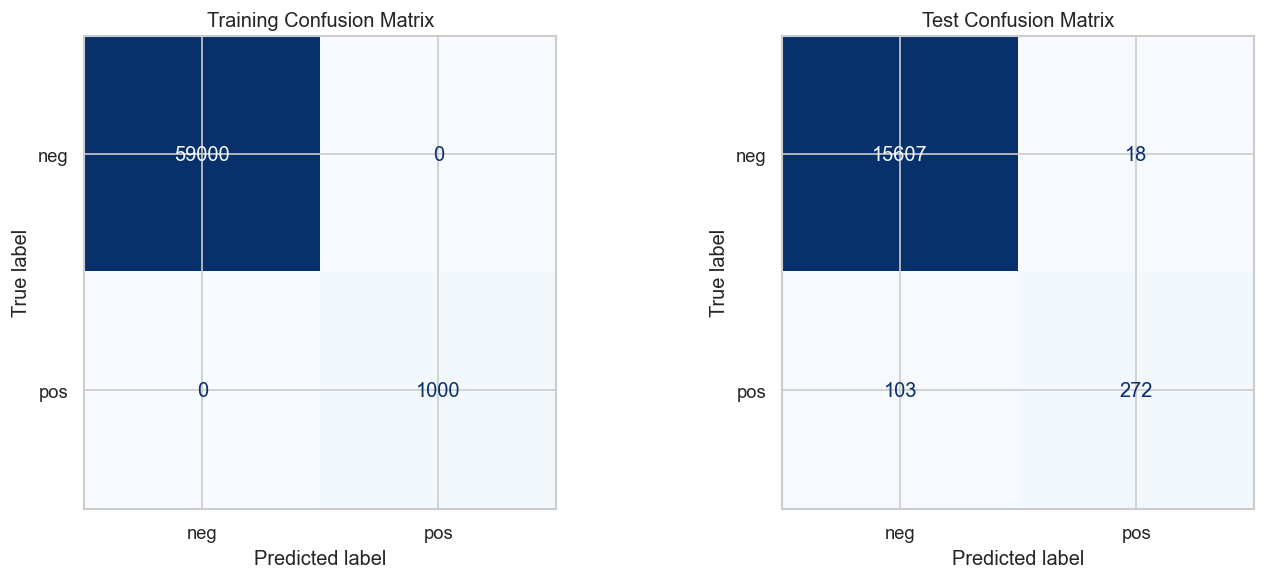

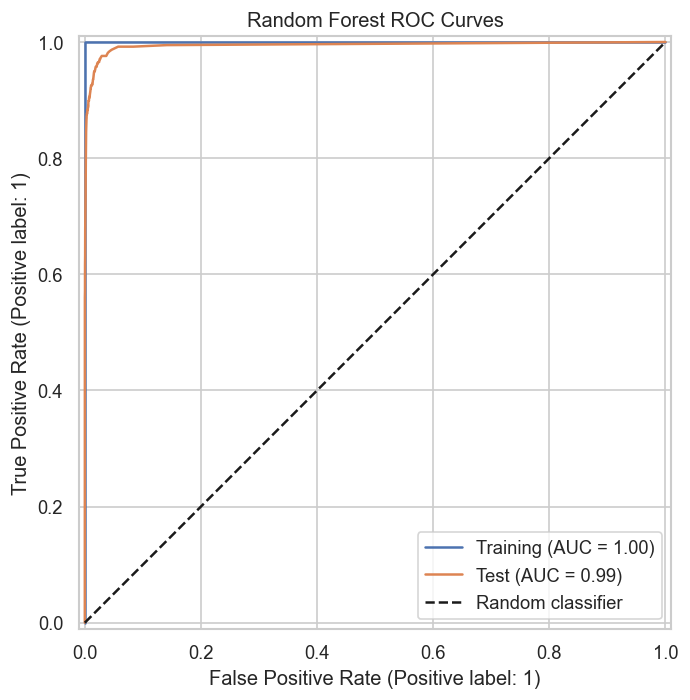

In [9]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    bootstrap=True,
    oob_score=True,
    class_weight=None,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf.fit(X_train_imputed, y_train)

rf_train_pred = rf.predict(X_train_imputed)
rf_test_pred = rf.predict(X_test_imputed)

rf_train_prob = rf.predict_proba(X_train_imputed)[:, 1]
rf_test_prob = rf.predict_proba(X_test_imputed)[:, 1]

rf_train_error = 1 - accuracy_score(y_train, rf_train_pred)
rf_test_error = 1 - accuracy_score(y_test, rf_test_pred)
rf_oob_error = 1 - rf.oob_score_

rf_results = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "Misclassification rate": [rf_train_error, rf_test_error],
    "AUC": [
        roc_auc_score(y_train, rf_train_prob),
        roc_auc_score(y_test, rf_test_prob)
    ]
})

display(rf_results.round(6))

print(f"OOB error: {rf_oob_error:.6f}")
print(f"Test error: {rf_test_error:.6f}")
print(f"OOB error - Test error: {rf_oob_error - rf_test_error:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_true, y_pred, title in [
    (axes[0], y_train, rf_train_pred, "Training Confusion Matrix"),
    (axes[1], y_test, rf_test_pred, "Test Confusion Matrix")
]:
    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_true, y_pred, labels=[0, 1]),
        display_labels=["neg", "pos"]
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(title)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_train, rf_train_prob, name="Training", ax=ax
)

RocCurveDisplay.from_predictions(
    y_test, rf_test_prob, name="Test", ax=ax
)

ax.plot([0, 1], [0, 1], "k--", label="Random classifier")
ax.set_title("Random Forest ROC Curves")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

OOB error is 0.5767%, about 0.18 percentage points below test error.
Positive-class recall is 272/375 = 72.53%, so low overall error does not mean all failures are detected.

### (d) Research class imbalance in random forest

 Class imbalance can be addressed using class weights, oversampling, or undersampling.
I use class_weight="balanced" to assign higher weights to the minority class.

,Dataset,Misclassification rate,AUC
0,Training,0.00000,1.000000
1,Test,0.01075,0.993263


OOB error: 0.007867
Test error: 0.010750
OOB error - Test error: -0.002883


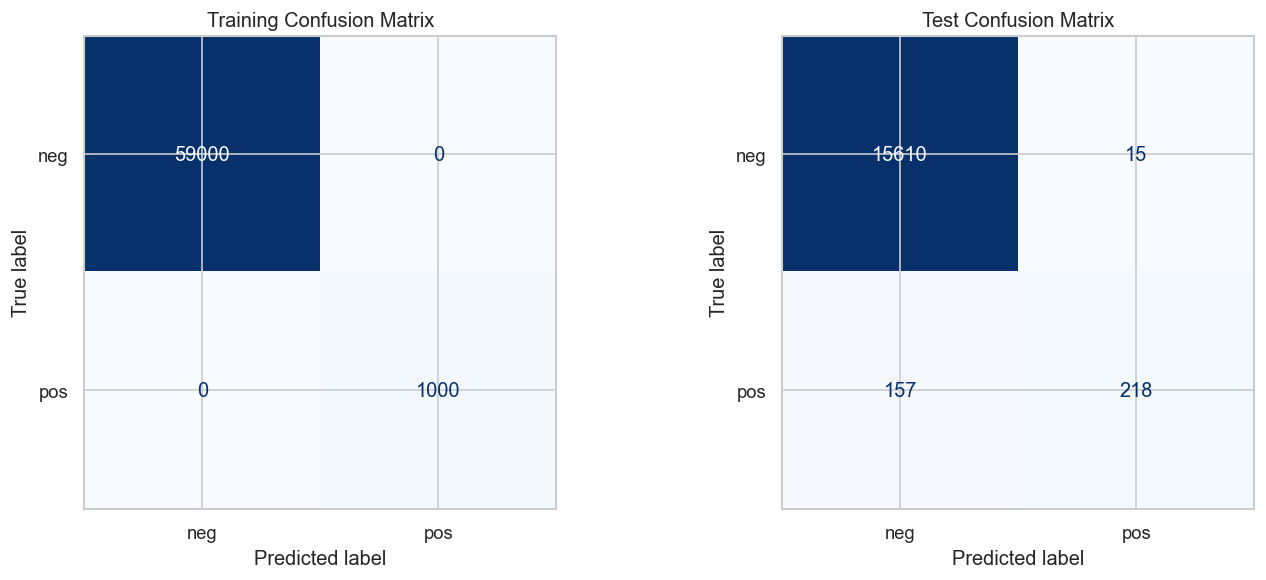

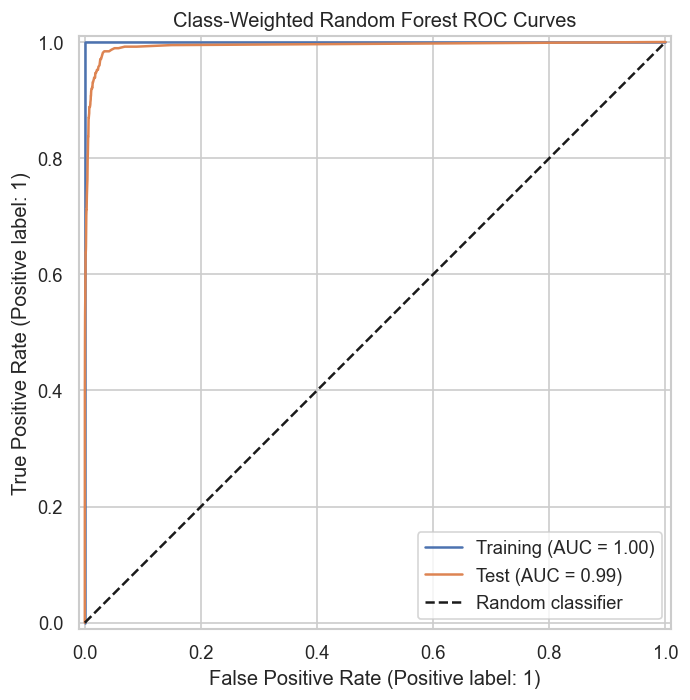

,Model,Test error,Test AUC,OOB error,False positives,False negatives,Positive recall
0,Standard RF,0.007563,0.994229,0.005767,18,103,0.725333
1,Weighted RF,0.010750,0.993263,0.007867,15,157,0.581333


In [10]:
rf_balanced = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    bootstrap=True,
    oob_score=True,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_balanced.fit(X_train_imputed, y_train)

rf_bal_train_pred = rf_balanced.predict(X_train_imputed)
rf_bal_test_pred = rf_balanced.predict(X_test_imputed)

rf_bal_train_prob = rf_balanced.predict_proba(X_train_imputed)[:, 1]
rf_bal_test_prob = rf_balanced.predict_proba(X_test_imputed)[:, 1]

rf_bal_train_error = 1 - accuracy_score(y_train, rf_bal_train_pred)
rf_bal_test_error = 1 - accuracy_score(y_test, rf_bal_test_pred)
rf_bal_oob_error = 1 - rf_balanced.oob_score_

rf_bal_results = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "Misclassification rate": [rf_bal_train_error, rf_bal_test_error],
    "AUC": [
        roc_auc_score(y_train, rf_bal_train_prob),
        roc_auc_score(y_test, rf_bal_test_prob)
    ]
})

display(rf_bal_results.round(6))

print(f"OOB error: {rf_bal_oob_error:.6f}")
print(f"Test error: {rf_bal_test_error:.6f}")
print(f"OOB error - Test error: {rf_bal_oob_error - rf_bal_test_error:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_true, y_pred, title in [
    (axes[0], y_train, rf_bal_train_pred, "Training Confusion Matrix"),
    (axes[1], y_test, rf_bal_test_pred, "Test Confusion Matrix")
]:
    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_true, y_pred, labels=[0, 1]),
        display_labels=["neg", "pos"]
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(title)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_train, rf_bal_train_prob, name="Training", ax=ax
)

RocCurveDisplay.from_predictions(
    y_test, rf_bal_test_prob, name="Test", ax=ax
)

ax.plot([0, 1], [0, 1], "k--", label="Random classifier")
ax.set_title("Class-Weighted Random Forest ROC Curves")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

comparison_rows = []

for name, predictions, probabilities, oob_error in [
    ("Standard RF", rf_test_pred, rf_test_prob, rf_oob_error),
    ("Weighted RF", rf_bal_test_pred, rf_bal_test_prob, rf_bal_oob_error)
]:
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    comparison_rows.append({
        "Model": name,
        "Test error": 1 - accuracy_score(y_test, predictions),
        "Test AUC": roc_auc_score(y_test, probabilities),
        "OOB error": oob_error,
        "False positives": fp,
        "False negatives": fn,
        "Positive recall": tp / (tp + fn)
    })

rf_comparison = pd.DataFrame(comparison_rows)
display(rf_comparison.round(6))

After weighting, test error increased from 0.7563% to 1.0750%, and test AUC decreased from 0.9942 to 0.9933.
Class weighting did not improve performance under these settings.

### (e) XGBoost and Model Trees

In [11]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBClassifier(
        booster="gbtree",
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_estimators=300,
        max_depth=4,
        learning_rate=0.1,
        reg_lambda=0,
        scale_pos_weight=1,
        random_state=RANDOM_STATE,
        n_jobs=4
    ))
])

alpha_grid = {
    "model__reg_alpha": [0.001, 0.01, 0.1, 1, 10]
}

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=alpha_grid,
    scoring="accuracy",
    cv=cv,
    refit=True,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

xgb_search.fit(X_train, y_train)

xgb_cv_results = pd.DataFrame({
    "Alpha": [
        params["model__reg_alpha"]
        for params in xgb_search.cv_results_["params"]
    ],
    "Mean CV error": 1 - xgb_search.cv_results_["mean_test_score"],
    "CV error SD": xgb_search.cv_results_["std_test_score"]
})

display(xgb_cv_results.sort_values("Mean CV error").round(6))

best_xgb = xgb_search.best_estimator_
xgb_cv_error = 1 - xgb_search.best_score_

print("Best alpha:", xgb_search.best_params_["model__reg_alpha"])
print(f"Selected model CV error: {xgb_cv_error:.6f}")

Fitting 5 folds for each of 5 candidates, totalling 25 fits
[CV] END .............................model__reg_alpha=0.001; total time=   3.0s
[CV] END .............................model__reg_alpha=0.001; total time=   2.4s
[CV] END .............................model__reg_alpha=0.001; total time=   2.3s
[CV] END .............................model__reg_alpha=0.001; total time=   2.4s
[CV] END .............................model__reg_alpha=0.001; total time=   2.5s
[CV] END ..............................model__reg_alpha=0.01; total time=   2.3s
[CV] END ..............................model__reg_alpha=0.01; total time=   2.4s
[CV] END ..............................model__reg_alpha=0.01; total time=   2.4s
[CV] END ..............................model__reg_alpha=0.01; total time=   2.5s
[CV] END ..............................model__reg_alpha=0.01; total time=   2.5s
[CV] END ...............................model__reg_alpha=0.1; total time=   2.5s
[CV] END ...............................model__re

,Alpha,Mean CV error,CV error SD
3,1.000,0.005200,0.000458
2,0.100,0.005250,0.000401
1,0.010,0.005333,0.000508
0,0.001,0.005383,0.000515
4,10.000,0.006233,0.000433


Best alpha: 1
Selected model CV error: 0.005200


,Dataset,Misclassification rate,AUC
0,Training,0.000283,0.999942
1,Test,0.005812,0.996201


CV error: 0.005200
Test error: 0.005812
Test error - CV error: 0.000613


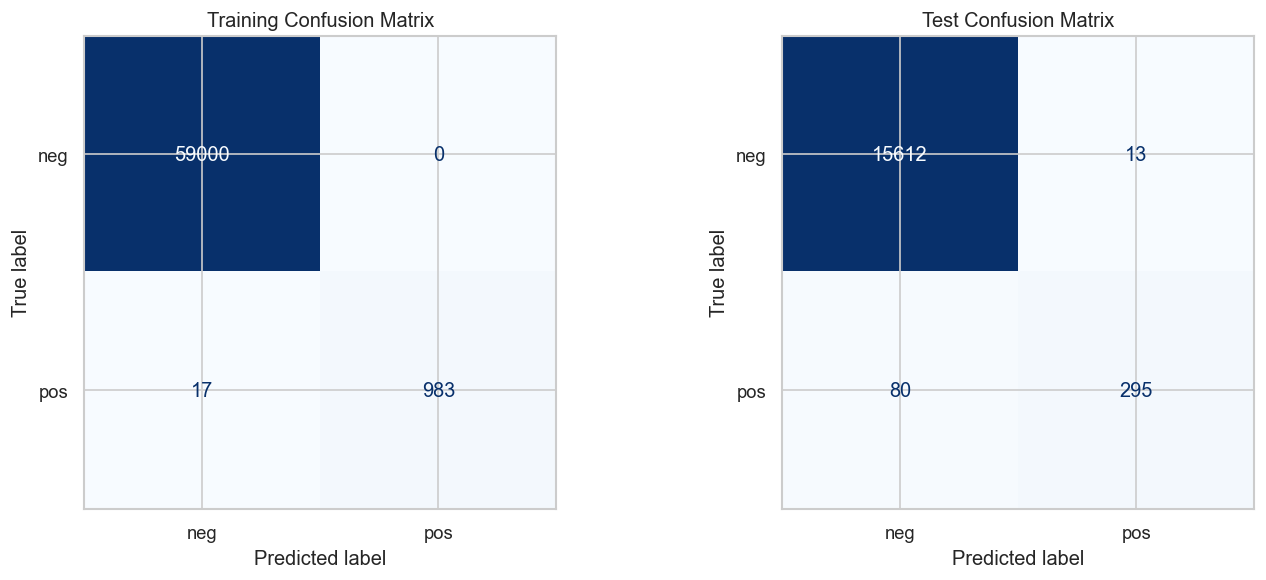

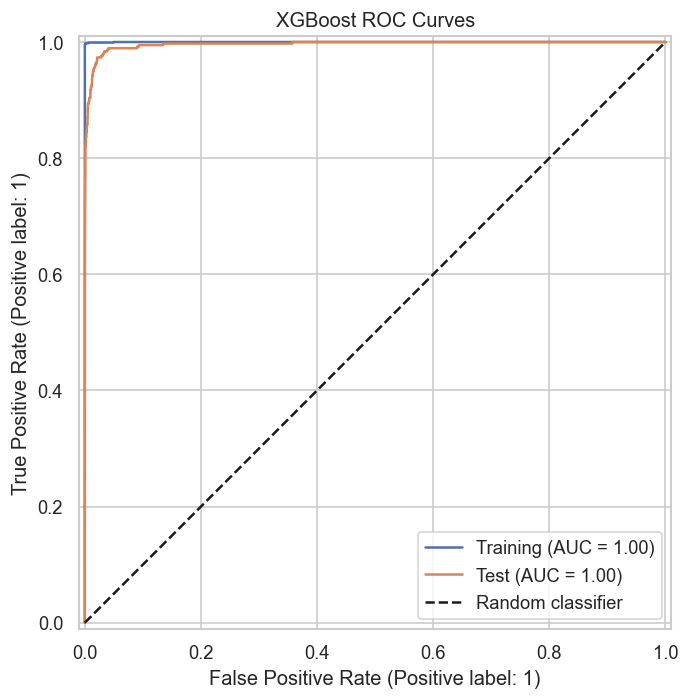

In [12]:
xgb_train_pred = best_xgb.predict(X_train)
xgb_test_pred = best_xgb.predict(X_test)

xgb_train_prob = best_xgb.predict_proba(X_train)[:, 1]
xgb_test_prob = best_xgb.predict_proba(X_test)[:, 1]

xgb_train_error = 1 - accuracy_score(y_train, xgb_train_pred)
xgb_test_error = 1 - accuracy_score(y_test, xgb_test_pred)

xgb_results = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "Misclassification rate": [xgb_train_error, xgb_test_error],
    "AUC": [
        roc_auc_score(y_train, xgb_train_prob),
        roc_auc_score(y_test, xgb_test_prob)
    ]
})

display(xgb_results.round(6))

print(f"CV error: {xgb_cv_error:.6f}")
print(f"Test error: {xgb_test_error:.6f}")
print(f"Test error - CV error: {xgb_test_error - xgb_cv_error:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_true, y_pred, title in [
    (axes[0], y_train, xgb_train_pred, "Training Confusion Matrix"),
    (axes[1], y_test, xgb_test_pred, "Test Confusion Matrix")
]:
    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_true, y_pred, labels=[0, 1]),
        display_labels=["neg", "pos"]
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(title)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_train, xgb_train_prob, name="Training", ax=ax
)

RocCurveDisplay.from_predictions(
    y_test, xgb_test_prob, name="Test", ax=ax
)

ax.plot([0, 1], [0, 1], "k--", label="Random classifier")
ax.set_title("XGBoost ROC Curves")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

The selected alpha is 1, with a mean 5-fold CV error of 0.5200%.
Training error is 0.0283%, and training AUC is 0.999942.
Test error is 0.5813% and test AUC is 0.996201, with 13 false positives and 80 false negatives.
Positive-class recall is 295/375 = 78.67%.

### (f) Use SMOTE to pre-process your data

In [13]:
smote_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(
        sampling_strategy="auto",
        k_neighbors=5,
        random_state=RANDOM_STATE
    )),
    ("model", XGBClassifier(
        booster="gbtree",
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_estimators=300,
        max_depth=4,
        learning_rate=0.1,
        reg_lambda=0,
        scale_pos_weight=1,
        random_state=RANDOM_STATE,
        n_jobs=4
    ))
])

smote_search = GridSearchCV(
    estimator=smote_pipeline,
    param_grid=alpha_grid,
    scoring="accuracy",
    cv=cv,
    refit=True,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

smote_search.fit(X_train, y_train)

smote_cv_results = pd.DataFrame({
    "Alpha": [
        params["model__reg_alpha"]
        for params in smote_search.cv_results_["params"]
    ],
    "Mean CV error": 1 - smote_search.cv_results_["mean_test_score"],
    "CV error SD": smote_search.cv_results_["std_test_score"]
})

display(smote_cv_results.sort_values("Mean CV error").round(6))

best_smote_xgb = smote_search.best_estimator_
smote_cv_error = 1 - smote_search.best_score_

print("Best alpha:", smote_search.best_params_["model__reg_alpha"])
print(f"Selected model CV error: {smote_cv_error:.6f}")

n_synthetic = sum(
    best_smote_xgb.named_steps["smote"].sampling_strategy_.values()
)

print("Original training observations:", len(y_train))
print("Synthetic observations added:", n_synthetic)
print("Resampled training observations:", len(y_train) + n_synthetic)

Fitting 5 folds for each of 5 candidates, totalling 25 fits


/Users/eliooooo/Library/Python/3.9/lib/python/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


[CV] END .............................model__reg_alpha=0.001; total time=   4.5s


/Users/eliooooo/Library/Python/3.9/lib/python/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


[CV] END .............................model__reg_alpha=0.001; total time=   4.0s


/Users/eliooooo/Library/Python/3.9/lib/python/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


... (44 outputs left out)

[CV] END ................................model__reg_alpha=10; total time=   4.1s


/Users/eliooooo/Library/Python/3.9/lib/python/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


,Alpha,Mean CV error,CV error SD
3,1.000,0.007733,0.000581
2,0.100,0.007867,0.000726
1,0.010,0.007900,0.000590
0,0.001,0.008250,0.000709
4,10.000,0.008800,0.000523


Best alpha: 1
Selected model CV error: 0.007733
Original training observations: 60000
Synthetic observations added: 58000
Resampled training observations: 118000


,Dataset,Misclassification rate,AUC
0,Training,0.001917,0.999766
1,Test,0.008125,0.993869


CV error: 0.007733
Test error: 0.008125
Test error - CV error: 0.000392


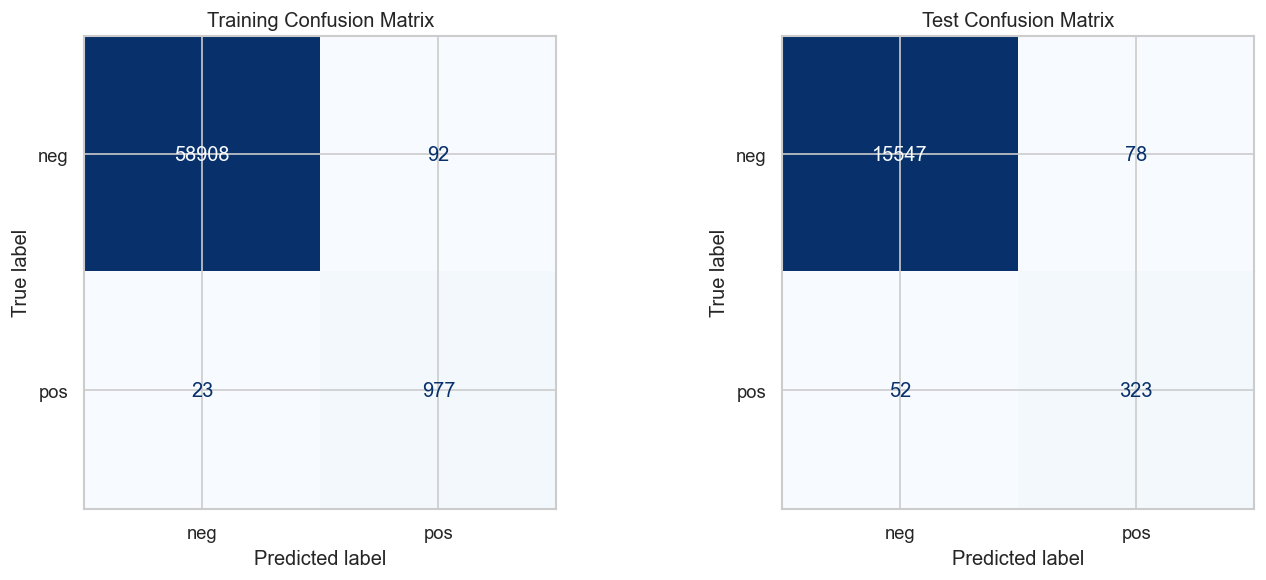

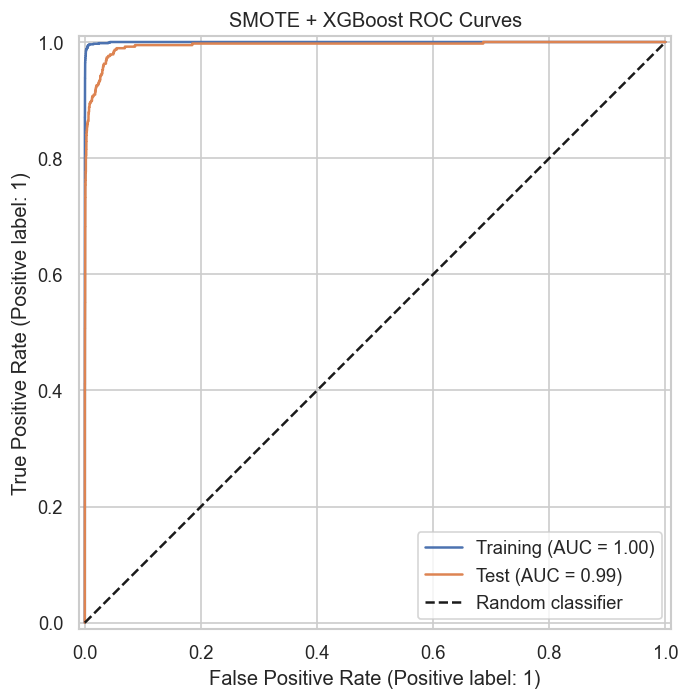

,Model,CV error,Test error,Test AUC,False positives,False negatives,Positive recall
0,XGBoost,0.005200,0.005812,0.996201,13,80,0.786667
1,SMOTE + XGBoost,0.007733,0.008125,0.993869,78,52,0.861333


In [14]:
smote_train_pred = best_smote_xgb.predict(X_train)
smote_test_pred = best_smote_xgb.predict(X_test)

smote_train_prob = best_smote_xgb.predict_proba(X_train)[:, 1]
smote_test_prob = best_smote_xgb.predict_proba(X_test)[:, 1]

smote_train_error = 1 - accuracy_score(y_train, smote_train_pred)
smote_test_error = 1 - accuracy_score(y_test, smote_test_pred)

smote_results = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "Misclassification rate": [smote_train_error, smote_test_error],
    "AUC": [
        roc_auc_score(y_train, smote_train_prob),
        roc_auc_score(y_test, smote_test_prob)
    ]
})

display(smote_results.round(6))

print(f"CV error: {smote_cv_error:.6f}")
print(f"Test error: {smote_test_error:.6f}")
print(f"Test error - CV error: {smote_test_error - smote_cv_error:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_true, y_pred, title in [
    (axes[0], y_train, smote_train_pred, "Training Confusion Matrix"),
    (axes[1], y_test, smote_test_pred, "Test Confusion Matrix")
]:
    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_true, y_pred, labels=[0, 1]),
        display_labels=["neg", "pos"]
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(title)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_train, smote_train_prob, name="Training", ax=ax
)

RocCurveDisplay.from_predictions(
    y_test, smote_test_prob, name="Test", ax=ax
)

ax.plot([0, 1], [0, 1], "k--", label="Random classifier")
ax.set_title("SMOTE + XGBoost ROC Curves")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

comparison_rows = []

for name, predictions, probabilities, cv_error in [
    ("XGBoost", xgb_test_pred, xgb_test_prob, xgb_cv_error),
    ("SMOTE + XGBoost", smote_test_pred, smote_test_prob, smote_cv_error)
]:
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    comparison_rows.append({
        "Model": name,
        "CV error": cv_error,
        "Test error": 1 - accuracy_score(y_test, predictions),
        "Test AUC": roc_auc_score(y_test, probabilities),
        "False positives": fp,
        "False negatives": fn,
        "Positive recall": tp / (tp + fn)
    })

xgb_comparison = pd.DataFrame(comparison_rows)
display(xgb_comparison.round(6))

The selected alpha is 1. Training error is 0.1917%, and training AUC is 0.999766.
CV error is 0.7733%, close to the test error of 0.8125%.
Compared with XGBoost without SMOTE, positive recall increased from 78.67% to 86.13%.
Test error increased from 0.5813% to 0.8125%, while test AUC decreased from 0.996201 to 0.993869.
SMOTE improves failure detection at the cost of more false alarms.

## 2. ISLR 6.6.3

Increasing $s$ relaxes the lasso constraint and makes the model more flexible.

**(a) iv. Steadily decrease.** Training RSS cannot increase as the feasible set expands. It becomes constant once the least-squares solution is feasible.

**(b) ii. Decrease and then increase.** Test RSS typically follows a U-shape as the model moves from underfitting to overfitting.

**(c) iii. Steadily increase.** Greater flexibility generally increases sensitivity to the training data.

**(d) iv. Steadily decrease.** A weaker constraint usually reduces squared bias.

**(e) v. Remain constant.** Irreducible error comes from noise and does not depend on $s$.

## 3. ISLR 6.6.5

Let $x_i=x_{i1}=x_{i2}$. Since the data are centered, $\hat{\beta}_0=0$. Assume $\lambda>0$.

**(a) Ridge optimization**

$$
\min_{\beta_1,\beta_2}
\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2
+\lambda(\beta_1^2+\beta_2^2).
$$

**(b) Equal ridge coefficients**

Let $t=\beta_1+\beta_2$. For a fixed $t$, the RSS is unchanged, and

$$
\beta_1^2+\beta_2^2
=\frac{t^2+(\beta_1-\beta_2)^2}{2}.
$$

The penalty is minimized when $\beta_1=\beta_2$. Therefore, $\hat{\beta}_1=\hat{\beta}_2$.

**(c) Lasso optimization**

$$
\min_{\beta_1,\beta_2}
\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2
+\lambda(|\beta_1|+|\beta_2|).
$$

**(d) Non-unique lasso coefficients**

Let $t^*$ minimize

$$
\sum_{i=1}^{2}(y_i-x_it)^2+\lambda|t|.
$$

Any same-sign pair with $\beta_1+\beta_2=t^*$ has the same RSS and penalty because $|\beta_1|+|\beta_2|=|t^*|$.

Thus, when $t^*\ne0$, all pairs are solutions. 

$$
(\hat{\beta}_1,\hat{\beta}_2)
=(a t^*,(1-a)t^*),\qquad 0\le a\le1,
$$

If $t^*=0$, the solution is uniquely $(0,0)$ for $\lambda>0$.

## 4. ISLR 8.4.5

**Majority vote: Red**

Six trees predict Red (probability above 0.5), while four predict Green. Therefore, the majority vote is Red.

**Average probability: Green**

$$
\bar{p}=\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}
=\frac{4.5}{10}=0.45.
$$

Since the average probability of Red is below 0.5, the prediction is Green.

## 5. ISLR 9.7.3

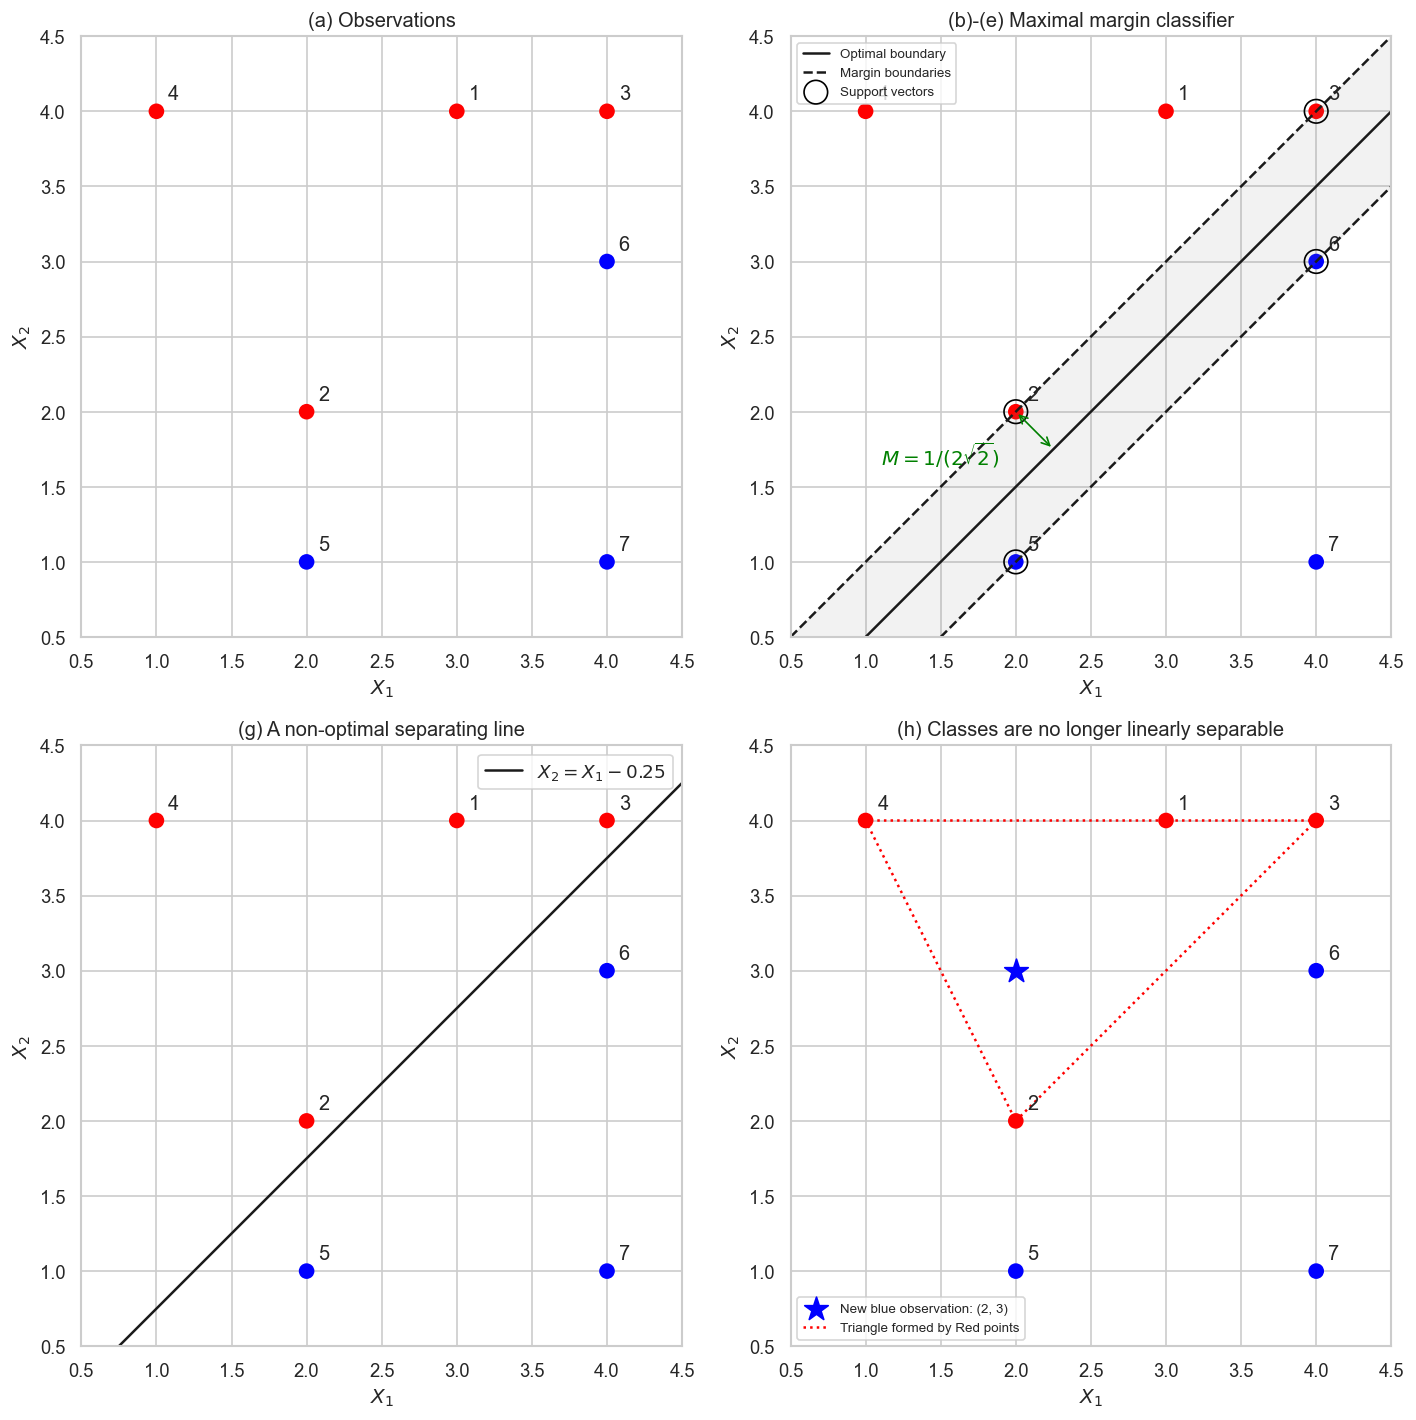

In [16]:
points = np.array([
    [3, 4],
    [2, 2],
    [4, 4],
    [1, 4],
    [2, 1],
    [4, 3],
    [4, 1]
])

colors = ["red"] * 4 + ["blue"] * 3
x_line = np.linspace(0.5, 4.5, 200)

fig, axes = plt.subplots(2, 2, figsize=(12, 12))

for ax in axes.flat:
    ax.scatter(points[:, 0], points[:, 1], c=colors, s=70)

    for i, (x, y) in enumerate(points, start=1):
        ax.annotate(str(i), (x, y), xytext=(7, 7),
                    textcoords="offset points")

    ax.set_xlim(0.5, 4.5)
    ax.set_ylim(0.5, 4.5)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.set_aspect("equal")

axes[0, 0].set_title("(a) Observations")

ax = axes[0, 1]
ax.plot(x_line, x_line - 0.5, "k-", label="Optimal boundary")
ax.plot(x_line, x_line, "k--", label="Margin boundaries")
ax.plot(x_line, x_line - 1, "k--")
ax.fill_between(x_line, x_line - 1, x_line, alpha=0.1, color="gray")

support_indices = [1, 2, 4, 5]
ax.scatter(
    points[support_indices, 0],
    points[support_indices, 1],
    s=200,
    facecolors="none",
    edgecolors="black",
    label="Support vectors"
)

ax.annotate(
    "",
    xy=(2, 2),
    xytext=(2.25, 1.75),
    arrowprops={"arrowstyle": "<->", "color": "green"}
)
ax.text(1.1, 1.65, r"$M=1/(2\sqrt{2})$", color="green")
ax.set_title("(b)-(e) Maximal margin classifier")
ax.legend(loc="upper left", fontsize=8)

ax = axes[1, 0]
ax.plot(x_line, x_line - 0.25, "k-", label="$X_2=X_1-0.25$")
ax.set_title("(g) A non-optimal separating line")
ax.legend()

ax = axes[1, 1]
ax.scatter(
    2, 3,
    color="blue",
    marker="*",
    s=220,
    label="New blue observation: (2, 3)"
)
ax.plot(
    [2, 4, 1, 2],
    [2, 4, 4, 2],
    color="red",
    linestyle=":",
    label="Triangle formed by Red points"
)
ax.set_title("(h) Classes are no longer linearly separable")
ax.legend(loc="lower left", fontsize=8)

plt.tight_layout()
plt.show()

**(a)** The seven observations are shown in the plot.

**(b)** The optimal separating hyperplane is

$$
0.5-X_1+X_2=0,
$$

or $X_2=X_1-0.5$.

**(c)** Classify as Red if $0.5-X_1+X_2>0$, and Blue otherwise. Thus,

$$
\beta_0=0.5,\qquad \beta_1=-1,\qquad \beta_2=1.
$$

**(d)** The margin boundaries are $X_2=X_1$ and $X_2=X_1-1$. The perpendicular distance from the separating line to either boundary is

$$
M=\frac{0.5}{\sqrt{(-1)^2+1^2}}
=\frac{1}{2\sqrt{2}}\approx0.354.
$$

The total width between the margin boundaries is $2M\approx0.707$.

**(e)** The support vectors are observations **2, 3, 5, and 6**:
$(2,2)$, $(4,4)$, $(2,1)$, and $(4,3)$.

**(f)** Observation 7, $(4,1)$, lies well outside the margin and is not a support vector. A sufficiently small movement leaves the optimal hyperplane unchanged.

**(g)** One non-optimal separating hyperplane is

$$
0.25-X_1+X_2=0.
$$

It separates the classes, but its minimum distance to the observations is only $0.25/\sqrt{2}$, smaller than the optimal margin.

**(h)** Add a Blue observation at $(2,3)$. It lies inside the triangle formed by Red observations 2, 3, and 4, so no straight line can separate all Red and Blue observations.